<a href="https://colab.research.google.com/github/Dimas-091206/Proyek-Akhir-Kelompok-9-Online-Retail-II/blob/main/Preprocessing_Online_Retail_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praproses Data: Klasifikasi UK vs non-UK (k-NN dan Naive Bayes)
**Mata Kuliah:** Pembelajaran Mesin

**Dataset:** Online Retail II

**Metode:** Klasifikasi

**Kelompok / anggota:** 9 (Dimas Faturohman, Faija Kulla Azmina, Kurniawan Aji Saputra Romadhon)


Notebook ini melanjutkan hasil notebook EDA (`Eksploratory_Data_Online_Retail_II.ipynb`). Masukannya adalah `data_bersih_pelanggan.csv` (satu baris = satu pelanggan) dan keluarannya adalah data latih/uji siap model, yang dipakai bersama oleh **ketiga anggota** supaya perbandingan antar varian adil.

In [22]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 100

try:
    from google.colab import drive
    drive.mount('/content/drive')
    FOLDER = '/content/drive/MyDrive/TugasAkhirPembelajaranMesin'
except ImportError:
    FOLDER = '.'
os.makedirs(FOLDER, exist_ok=True)

RANDOM_STATE = 42
UKURAN_UJI = 0.20
GUNAKAN_LOG = True

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Langkah 1 - Muat hasil EDA

In [23]:
BERKAS = f'{FOLDER}/data_bersih_pelanggan.csv'
if not os.path.exists(BERKAS):
    raise FileNotFoundError(f'{BERKAS} tidak ditemukan. Jalankan notebook EDA sampai Langkah 7, '
                            f'atau letakkan berkas itu di {FOLDER}.')
data = pd.read_csv(BERKAS, dtype={'Customer ID': str})
print('bentuk data:', data.shape, '(EDA: 5.852 pelanggan x 14 kolom)')
print('sesuai hasil EDA:', data.shape == (5852, 14))
display(data.head())
data.info()

bentuk data: (5852, 14) (EDA: 5.852 pelanggan x 14 kolom)
sesuai hasil EDA: True


,Customer ID,total_belanja,frekuensi,recency,tenure_hari,produk_unik,total_item,n_faktur_batal,rata_nilai_faktur,nilai_batal,total_belanja_bersih,negara,n_negara,kelompok_negara
0,12346,"77,352.960",3,325,647,25,74239,1.000,"25,784.320","-77,183.600",169.360,United Kingdom,1,UK
1,12347,"4,921.530",8,2,404,126,2967,0.000,615.191,0.000,"4,921.530",Iceland,1,non-UK
2,12348,"1,658.400",5,75,438,24,2704,0.000,331.680,0.000,"1,658.400",Finland,1,non-UK
3,12349,"3,678.690",3,18,589,137,1621,1.000,"1,226.230",-24.150,"3,654.540",Italy,1,non-UK
4,12350,294.400,1,310,310,16,196,0.000,294.400,0.000,294.400,Norway,1,non-UK


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5852 entries, 0 to 5851
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer ID           5852 non-null   object 
 1   total_belanja         5852 non-null   float64
 2   frekuensi             5852 non-null   int64  
 3   recency               5852 non-null   int64  
 4   tenure_hari           5852 non-null   int64  
 5   produk_unik           5852 non-null   int64  
 6   total_item            5852 non-null   int64  
 7   n_faktur_batal        5852 non-null   float64
 8   rata_nilai_faktur     5852 non-null   float64
 9   nilai_batal           5852 non-null   float64
 10  total_belanja_bersih  5852 non-null   float64
 11  negara                5852 non-null   object 
 12  n_negara              5852 non-null   int64  
 13  kelompok_negara       5852 non-null   object 
dtypes: float64(5), int64(6), object(3)
memory usage: 640.2+ KB


## Langkah 2 - Pilih fitur dan target

Keputusan mengikuti Bagian C proposal dan temuan EDA. Kolom yang **tidak boleh** menjadi fitur dicatat bersama alasannya.

In [24]:
TARGET_ASAL = 'kelompok_negara'
FITUR = ['recency', 'frekuensi', 'total_belanja', 'produk_unik', 'total_item', 'n_faktur_batal']

keputusan_kolom = pd.DataFrame([
    ['Customer ID',          'Dibuang',  'Identifier (nomor pelanggan), bukan besaran. Hanya untuk menelusuri.'],
    ['kelompok_negara',      'TARGET',   'Kelas yang diprediksi: UK vs non-UK.'],
    ['negara',               'Dibuang',  'Kebocoran definisional: kelompok_negara dibentuk dari kolom ini.'],
    ['n_negara',             'Dibuang',  'Kebocoran halus: berasal dari kolom Country yang sama dengan target.'],
    ['recency',              'Fitur',    'Hari sejak pembelian terakhir.'],
    ['frekuensi',            'Fitur',    'Jumlah faktur pembelian berbeda.'],
    ['total_belanja',        'Fitur',    'Total nilai pembelian kotor (GBP).'],
    ['produk_unik',          'Fitur',    'Jumlah kode produk berbeda yang dibeli.'],
    ['total_item',           'Fitur',    'Jumlah unit seluruh pembelian (berkorelasi 0,87 dengan total_belanja).'],
    ['n_faktur_batal',       'Fitur',    'Jumlah faktur pembatalan.'],
    ['tenure_hari',          'Dibuang',  'Tidak masuk daftar fitur proposal (Bagian C).'],
    ['rata_nilai_faktur',    'Dibuang',  'Turunan langsung total_belanja/frekuensi; redundan (bocor pada regresi, bukan klasifikasi).'],
    ['nilai_batal',          'Dibuang',  'Turunan dari pembatalan; redundan dengan n_faktur_batal.'],
    ['total_belanja_bersih', 'Dibuang',  'Memuat total_belanja; redundan.'],
], columns=['Kolom', 'Peran', 'Alasan'])
display(keputusan_kolom)

TERLARANG = {'negara', 'n_negara', 'kelompok_negara', 'Customer ID'}
assert TERLARANG.isdisjoint(FITUR), 'Ada kolom terlarang di daftar fitur!'
assert set(FITUR + [TARGET_ASAL]).issubset(data.columns)
assert set(keputusan_kolom['Kolom']) == set(data.columns), 'Ada kolom data yang belum diputuskan'
print('pengaman lolos: fitur =', FITUR)

,Kolom,Peran,Alasan
0,Customer ID,Dibuang,"Identifier (nomor pelanggan), bukan besaran. H..."
1,kelompok_negara,TARGET,Kelas yang diprediksi: UK vs non-UK.
2,negara,Dibuang,Kebocoran definisional: kelompok_negara dibent...
3,n_negara,Dibuang,Kebocoran halus: berasal dari kolom Country ya...
4,recency,Fitur,Hari sejak pembelian terakhir.
5,frekuensi,Fitur,Jumlah faktur pembelian berbeda.
6,total_belanja,Fitur,Total nilai pembelian kotor (GBP).
7,produk_unik,Fitur,Jumlah kode produk berbeda yang dibeli.
8,total_item,Fitur,"Jumlah unit seluruh pembelian (berkorelasi 0,8..."
9,n_faktur_batal,Fitur,Jumlah faktur pembatalan.


pengaman lolos: fitur = ['recency', 'frekuensi', 'total_belanja', 'produk_unik', 'total_item', 'n_faktur_batal']


## Langkah 3 - Validasi kualitas data tingkat pelanggan

EDA sudah membersihkan data transaksi. Di sini dipastikan tabel pelanggan hasil agregasi benar-benar sehat sebelum dipakai.

In [25]:
df = data[['Customer ID'] + FITUR + [TARGET_ASAL]].copy()

print('Nilai kosong per kolom:'); print(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else '  tidak ada')
print('\nCustomer ID ganda     :', df['Customer ID'].duplicated().sum(), '(harus 0: satu baris = satu pelanggan)')
print('baris identik penuh   :', df.duplicated().sum())

# n_faktur_batal terbaca float karena ada NaN yang diisi nol saat agregasi; kembalikan ke bilangan bulat
df['n_faktur_batal'] = df['n_faktur_batal'].round().astype(int)

# Aturan rentang yang masuk akal (nilai di luar ini menandakan kesalahan, bukan pencilan nyata)
aturan = {
    'recency': df['recency'] >= 0,
    'frekuensi': df['frekuensi'] >= 1,
    'total_belanja': df['total_belanja'] > 0,
    'produk_unik': df['produk_unik'] >= 1,
    'total_item': df['total_item'] >= 1,
    'n_faktur_batal': df['n_faktur_batal'] >= 0,
}
print('\nPemeriksaan rentang (jumlah baris yang melanggar):')
for k, v in aturan.items():
    print(f'  {k:15s}: {(~v).sum()}')
assert all(v.all() for v in aturan.values()), 'Ada nilai mustahil pada fitur'
assert not np.isinf(df[FITUR]).any().any()
display(df[FITUR].describe().T)

Nilai kosong per kolom:
  tidak ada

Customer ID ganda     : 0 (harus 0: satu baris = satu pelanggan)
baris identik penuh   : 0

Pemeriksaan rentang (jumlah baris yang melanggar):
  recency        : 0
  frekuensi      : 0
  total_belanja  : 0
  produk_unik    : 0
  total_item     : 0
  n_faktur_batal : 0


,count,mean,std,min,25%,50%,75%,max
recency,"5,852.000",199.732,208.523,0.000,25.000,95.000,379.000,738.000
frekuensi,"5,852.000",6.253,12.749,1.000,1.000,3.000,7.000,373.000
total_belanja,"5,852.000","2,916.709","14,306.866",2.950,339.575,856.020,"2,241.030","580,987.040"
produk_unik,"5,852.000",82.190,116.500,1.000,19.000,45.000,103.000,"2,546.000"
total_item,"5,852.000","1,794.043","8,890.843",1.000,189.000,484.500,"1,352.500","367,072.000"
n_faktur_batal,"5,852.000",1.240,3.331,0.000,0.000,0.000,1.000,93.000


## Langkah 4 - Encoding target dan garis dasar

In [26]:
PETA_KELAS = {'UK': 0, 'non-UK': 1}          # kelas positif = non-UK (kelas minoritas yang paling perlu dikenali)
NAMA_KELAS = {0: 'UK', 1: 'non-UK'}
df['target'] = df[TARGET_ASAL].map(PETA_KELAS)
assert df['target'].notna().all(), 'Ada label di luar UK/non-UK'
df['target'] = df['target'].astype(int)

hitung = df['target'].value_counts().sort_index()
print('Sebaran kelas:')
for k, v in hitung.items():
    print(f'  {k} = {NAMA_KELAS[k]:7s}: {v:5d} pelanggan ({v/len(df)*100:.2f}%)')
GARIS_DASAR = hitung.max() / len(df)
print(f'\nGaris dasar (selalu menebak kelas mayoritas): {GARIS_DASAR:.2%}')
print('=> model yang akurasinya di sekitar angka ini belum belajar apa pun; gunakan juga recall/precision/F1 kelas non-UK.')

Sebaran kelas:
  0 = UK     :  5334 pelanggan (91.15%)
  1 = non-UK :   518 pelanggan (8.85%)

Garis dasar (selalu menebak kelas mayoritas): 91.15%
=> model yang akurasinya di sekitar angka ini belum belajar apa pun; gunakan juga recall/precision/F1 kelas non-UK.


**Keputusan encoding:** UK = 0 dan non-UK = 1. Kelas **non-UK dijadikan kelas positif** karena itu kelas minoritas; recall dan precision pada Tahap 2 akan menjawab "seberapa baik model mengenali pelanggan non-UK".

## Langkah 5 - Pencilan dan kemencengan

Temuan EDA: sebaran fitur sangat menceng ke kanan dan ada pelanggan bernilai ekstrem yang **nyata** (bukan kesalahan). Keputusannya:
- Pencilan **tidak dibuang** (tidak ada batas yang bisa dibela; 1,5xIQR menandai terlalu banyak baris dan pelanggan bernilai besar justru informatif).
- Kemencengan ditangani dengan **transformasi log1p**, karena k-NN menghitung jarak (nilai besar mendominasi) dan Naive Bayes Gaussian mengasumsikan sebaran mendekati normal.

,skewness_mentah,skewness_log1p,di_luar_1.5xIQR,persen
recency,0.894,-0.549,0,0.000
frekuensi,12.040,1.002,424,7.245
total_belanja,25.331,0.269,619,10.578
produk_unik,6.221,-0.257,451,7.707
total_item,21.824,0.057,603,10.304
n_faktur_batal,11.082,1.468,827,14.132


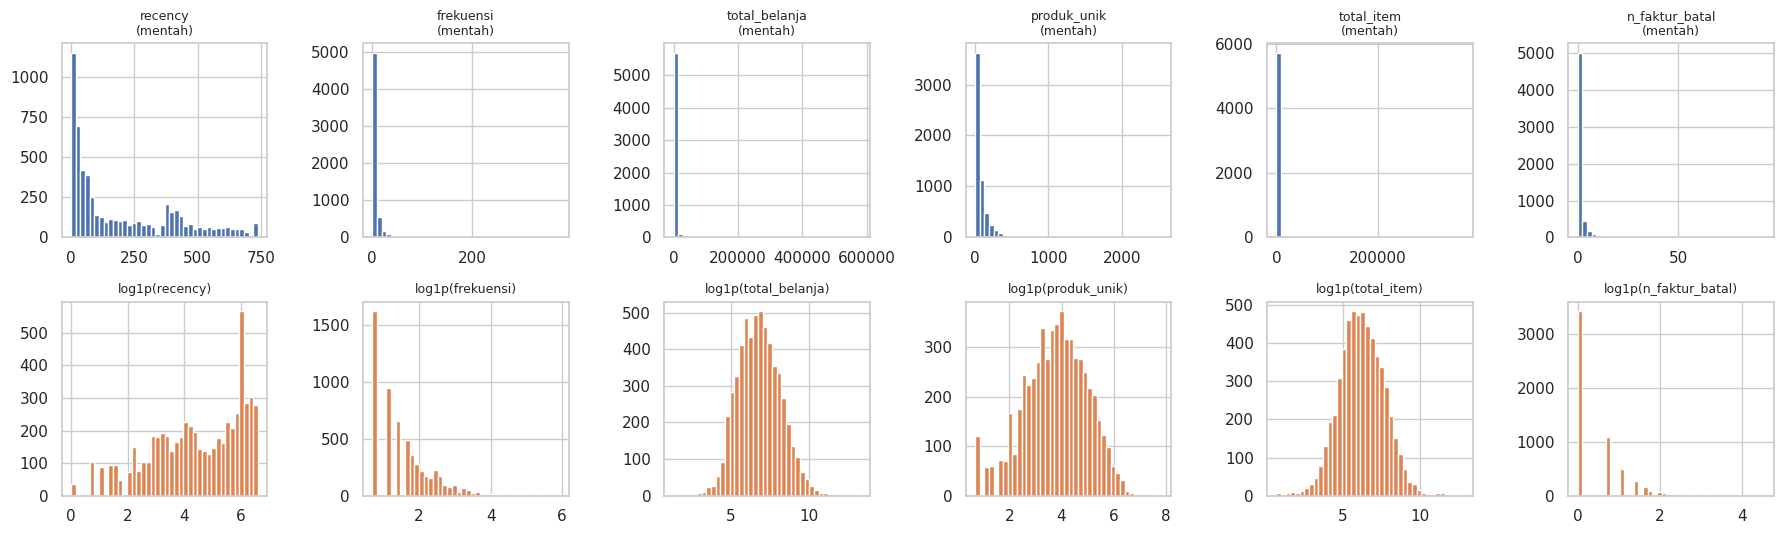

In [27]:
tabel = pd.DataFrame({
    'skewness_mentah': df[FITUR].skew(),
    'skewness_log1p': np.log1p(df[FITUR]).skew(),
})
q1, q3 = df[FITUR].quantile(0.25), df[FITUR].quantile(0.75)
iqr = q3 - q1
tabel['di_luar_1.5xIQR'] = ((df[FITUR] < q1 - 1.5 * iqr) | (df[FITUR] > q3 + 1.5 * iqr)).sum()
tabel['persen'] = tabel['di_luar_1.5xIQR'] / len(df) * 100
display(tabel)

fig, ax = plt.subplots(2, 6, figsize=(18, 5.5))
for i, f in enumerate(FITUR):
    ax[0, i].hist(df[f], bins=40); ax[0, i].set_title(f'{f}\n(mentah)', fontsize=9)
    ax[1, i].hist(np.log1p(df[f]), bins=40, color='#dd8452'); ax[1, i].set_title(f'log1p({f})', fontsize=9)
plt.tight_layout(); plt.show()

**Tafsir.** Lima dari enam fitur sangat menceng ke kanan pada data mentah (skewness 6 sampai 25, tertinggi `total_belanja` 25,3), dan log1p menurunkannya menjadi sekitar -0,3 sampai 1,5, sehingga sebarannya jauh lebih simetris. `recency` memang tidak menceng parah (0,89) dan tidak punya pencilan menurut 1,5xIQR; setelah log ia justru sedikit menceng ke kiri (-0,55), jadi manfaat log di sini kecil, tetapi tetap dipakai agar seluruh fitur diperlakukan seragam. `n_faktur_batal` paling banyak ditandai di luar pagar IQR (14,1%) karena sebagian besar pelanggan bernilai nol; `log1p` aman terhadap nol (berbeda dengan `log`). Tidak ada baris yang dibuang. _(Tulis ulang dengan kalimat sendiri.)_

## Langkah 6 - Pembagian data latih/uji (berstrata)

Karena kelas non-UK hanya sekitar 9%, pembagian harus **berstrata** (`stratify=y`) agar proporsi kelas sama pada data latih dan uji. Pembagian dilakukan **sebelum** penskalaan.

In [28]:
X = df[FITUR]
y = df['target']
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X, y, test_size=UKURAN_UJI, stratify=y, random_state=RANDOM_STATE)

ringkas = pd.DataFrame({
    'jumlah': [len(y_latih), len(y_uji)],
    'non-UK': [int(y_latih.sum()), int(y_uji.sum())],
    'persen_non-UK': [y_latih.mean() * 100, y_uji.mean() * 100],
}, index=['latih', 'uji'])
display(ringkas)
print(f'proporsi non-UK keseluruhan: {y.mean()*100:.2f}%')
assert abs(y_latih.mean() - y_uji.mean()) < 0.005, 'Stratifikasi gagal'
assert set(X_latih.index).isdisjoint(X_uji.index), 'Data latih dan uji beririsan!'

,jumlah,non-UK,persen_non-UK
latih,4681,414,8.844
uji,1171,104,8.881


proporsi non-UK keseluruhan: 8.85%


## Langkah 7 - Transformasi log dan penskalaan

Pipeline: `log1p` lalu `StandardScaler`. **`fit` hanya pada data latih**; data uji hanya `transform`. Pipeline disimpan agar aplikasi web memperlakukan masukan pengguna dengan cara yang persis sama.

In [29]:
langkah = []
if GUNAKAN_LOG:
    langkah.append(('log1p', FunctionTransformer(np.log1p, validate=False)))
langkah.append(('skala', StandardScaler()))
praproses = Pipeline(langkah)

praproses.fit(X_latih)                                   # belajar HANYA dari data latih
X_latih_skala = pd.DataFrame(praproses.transform(X_latih), columns=FITUR, index=X_latih.index)
X_uji_skala = pd.DataFrame(praproses.transform(X_uji), columns=FITUR, index=X_uji.index)

print('Data latih setelah praproses (rata-rata mendekati 0, simpangan baku mendekati 1):')
display(X_latih_skala.describe().loc[['mean', 'std', 'min', 'max']])
print('Data uji (TIDAK persis 0 dan 1, itu benar karena tidak ikut belajar):')
display(X_uji_skala.describe().loc[['mean', 'std']])
assert np.allclose(X_latih_skala.mean(), 0, atol=1e-6) and np.allclose(X_latih_skala.std(ddof=0), 1, atol=1e-6)

Data latih setelah praproses (rata-rata mendekati 0, simpangan baku mendekati 1):


,recency,frekuensi,total_belanja,produk_unik,total_item,n_faktur_batal
mean,0.000,0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.791,-1.061,-3.957,-2.541,-3.752,-0.701
max,1.372,4.730,4.717,2.916,4.492,5.457


Data uji (TIDAK persis 0 dan 1, itu benar karena tidak ikut belajar):


,recency,frekuensi,total_belanja,produk_unik,total_item,n_faktur_batal
mean,-0.008,0.017,0.026,0.048,0.011,0.056
std,1.023,1.035,1.032,1.004,1.035,1.043


## Langkah 8 - Uji kelayakan data

In [30]:
# 1) Tidak ada NaN/inf setelah transformasi
for nama, m in [('latih', X_latih_skala), ('uji', X_uji_skala)]:
    assert np.isfinite(m.values).all(), f'NaN/inf pada data {nama}'
print('tidak ada NaN/inf pada data latih maupun uji')

# 2) Garis dasar pada data uji (model dummy yang selalu menebak UK)
dummy = DummyClassifier(strategy='most_frequent').fit(X_latih_skala, y_latih)
pred = dummy.predict(X_uji_skala)
print(f'\nModel dummy pada data uji: akurasi = {accuracy_score(y_uji, pred):.2%}, '
      f'recall non-UK = {recall_score(y_uji, pred, pos_label=1):.2%}')
print('=> inilah batas bawah: model sungguhan harus mengalahkan recall 0% pada non-UK, bukan hanya akurasi.')

# 3) Kekuatan hubungan fitur dengan target (korelasi titik-biserial pada data latih)
kor = X_latih_skala.apply(lambda s: s.corr(y_latih)).sort_values(key=abs, ascending=False)
display(kor.to_frame('korelasi dengan target (non-UK = 1)'))
print('Korelasi terbesar:', f'{kor.abs().max():.2f}', '-> jika kecil, hasil klasifikasi memang diperkirakan lemah (sesuai temuan EDA), bukan karena praproses salah.')

tidak ada NaN/inf pada data latih maupun uji

Model dummy pada data uji: akurasi = 91.12%, recall non-UK = 0.00%
=> inilah batas bawah: model sungguhan harus mengalahkan recall 0% pada non-UK, bukan hanya akurasi.


,korelasi dengan target (non-UK = 1)
total_item,0.075
total_belanja,0.071
frekuensi,-0.030
produk_unik,0.022
recency,-0.018
n_faktur_batal,0.017


Korelasi terbesar: 0.08 -> jika kecil, hasil klasifikasi memang diperkirakan lemah (sesuai temuan EDA), bukan karena praproses salah.


## Langkah 9 - Simpan keluaran

In [31]:
# Rentang nilai fitur dari seluruh data bersih: dipakai aplikasi web untuk membatasi isian pengguna
rentang = {f: {'min': float(df[f].min()), 'maks': float(df[f].max()),
               'median': float(df[f].median())} for f in FITUR}

# Data (mentah = sebelum transformasi; skala = sesudah log1p + StandardScaler)
X_latih.assign(target=y_latih).to_csv(f'{FOLDER}/latih_mentah.csv')
X_uji.assign(target=y_uji).to_csv(f'{FOLDER}/uji_mentah.csv')
X_latih_skala.assign(target=y_latih).to_csv(f'{FOLDER}/latih_skala.csv')
X_uji_skala.assign(target=y_uji).to_csv(f'{FOLDER}/uji_skala.csv')

joblib.dump(praproses, f'{FOLDER}/praproses.joblib')
meta = {'fitur': FITUR, 'target': 'target', 'kelas': {str(k): v for k, v in NAMA_KELAS.items()},
        'kelas_positif': 'non-UK', 'random_state': RANDOM_STATE, 'ukuran_uji': UKURAN_UJI,
        'gunakan_log': GUNAKAN_LOG, 'jumlah_latih': int(len(y_latih)), 'jumlah_uji': int(len(y_uji)),
        'garis_dasar_kelas_mayoritas': float(GARIS_DASAR), 'rentang_fitur': rentang}
json.dump(meta, open(f'{FOLDER}/meta_praproses.json', 'w'), ensure_ascii=False, indent=2)
keputusan_kolom.to_csv(f'{FOLDER}/keputusan_kolom_praproses.csv', index=False)

# Uji ulang: pipeline yang dimuat dari berkas harus memberi hasil identik
ulang = joblib.load(f'{FOLDER}/praproses.joblib').transform(X_uji)
assert np.allclose(ulang, X_uji_skala.values)
print('pipeline tersimpan dan terbukti memberi hasil identik setelah dimuat ulang')
print('\nBerkas tersimpan di', os.path.abspath(FOLDER) + ':')
for b in ['latih_mentah.csv', 'uji_mentah.csv', 'latih_skala.csv', 'uji_skala.csv', 'praproses.joblib',
          'meta_praproses.json', 'keputusan_kolom_praproses.csv']:
    print(f'  {b:32s} {os.path.getsize(f"{FOLDER}/{b}")/1024:8.1f} KB')

pipeline tersimpan dan terbukti memberi hasil identik setelah dimuat ulang

Berkas tersimpan di /content/drive/MyDrive/TugasAkhirPembelajaranMesin:
  latih_mentah.csv                    135.1 KB
  uji_mentah.csv                       33.9 KB
  latih_skala.csv                     569.8 KB
  uji_skala.csv                       142.6 KB
  praproses.joblib                      1.7 KB
  meta_praproses.json                   0.9 KB
  keputusan_kolom_praproses.csv         1.0 KB
